# Qiskit Fall Fest 2026 — Phase 1: PS-C1, H₂ Ground-State Energy (VQE)
**Team X** — Shivansh Kumar and Aparna Bhadoriya

This notebook re-runs the whole pipeline (cell 3) and then displays the tables and figures it generates. All numbers in the text below are read from `results/tables/*.csv` (see `README.md`, rebuilt by `src/build_docs.py`).

**Summary (details in the tables below):**
- Exact reference E_FCI = −1.1373060358 Ha; chemical accuracy = 1.6 mHa. Ideal VQE reaches it to ~1e-7 mHa.
- Required A vs B benchmark: the 2-qubit circuit compiles identically on both (0 SWAPs); raw noisy error ≈ 24–26 mHa.
- Mitigation (readout inversion + parity postselection + pre-specified linear ZNE) cuts the bias a lot, but at 4096 shots the run-to-run std is large, so chemical accuracy is **not** reliably reached; see the multi-seed table.
- A 4-qubit routing stress test (not a chemistry result) shows topology effects: Processor A needs SWAPs, B fewer, D (K4 core) none.

In [1]:
# Environment configuration and imports
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML

# Add src to Python path
sys.path.insert(0, str(Path(".").resolve()))

from src.problem import (
    hamiltonian_2q,
    hamiltonian_4q,
    exact_ground_energy,
    EXACT_REFERENCE_ENERGY,
    CHEMICAL_ACCURACY,
    TERMS_2Q,
    NUCLEAR_REPULSION
)
from src.processors import (
    load_processor,
    get_coupling_map,
    get_noise_model,
    hea_ansatz,
    compact_chemistry_ansatz,
    full_entangling_4q_ansatz,
    with_measurement,
    run_vqe_ideal,
    ideal_energy
)
from src.routing import (
    compile_circuit,
    analyze_routing,
    benchmark_4qubit_architecture_routing
)
from src.metrics import (
    run_full_benchmark,
    NoisyEnergyEvaluator,
    run_zero_noise_extrapolation
)
from src.visualization import (
    save_processor_graphs,
    plot_vqe_convergence,
    plot_error_mitigation_results,
    plot_4qubit_routing_overhead
)

print("Libraries imported successfully!")
print(f"Classical FCI Reference Energy: {EXACT_REFERENCE_ENERGY:.8f} Ha")
print(f"Chemical Accuracy Threshold:   {CHEMICAL_ACCURACY * 1000:.2f} mHa ({CHEMICAL_ACCURACY:.5f} Ha)")


Libraries imported successfully!
Classical FCI Reference Energy: -1.13730604 Ha
Chemical Accuracy Threshold:   1.60 mHa (0.00160 Ha)


## 0. Run the full pipeline

In [2]:
# Re-run the complete benchmark (about 30 s). Regenerates every CSV and figure used below.
_ = run_full_benchmark()

=== Step 1: Rendering LaTeX equation assets ===


=== Step 2: Ideal VQE Convergence ===
[HEA reps=1] Optimized Energy: -1.1373060356 Ha (Error: 2.0267e-07 mHa)


[HEA reps=2] Optimized Energy: -1.1373060354 Ha (Error: 3.6788e-07 mHa)
[Compact Singlet] Optimized Energy: -1.1373060355 Ha (Error: 2.2848e-07 mHa)


=== Step 3: Architecture Transpilation & Baseline Noisy Execution ===


=== Step 4: Error Mitigation Study (multi-seed, pre-specified linear ZNE) ===


                                       stage  shots  energy_error_hartree  std_hartree  frac_runs_within_chem_acc
0                               1. Raw Noisy   4096              0.024372     0.004911                        0.0
1                       2. Readout Mitigated   4096              0.007410     0.005042                        0.1
2                      3. Readout + Symmetry   4096              0.004873     0.004510                        0.2
3            4. Readout+Sym+ZNE (linear 1,3)   4096              0.001902     0.009205                        0.1
4  5. ZNE quadratic (1,3,5), comparison only   4096              0.004309     0.011836                        0.0
5                               1. Raw Noisy  32768              0.022824     0.001673                        0.0
6                       2. Readout Mitigated  32768              0.005460     0.001720                        0.0
7                      3. Readout + Symmetry  32768              0.004109     0.001708  

  architecture  compiled_cx  swap_count  compiled_depth  shots  n_runs  hellinger_fidelity_mean  hellinger_fidelity_std  hellinger_fidelity_sem  paired_gain_vs_processor_A  paired_gain_sem
0  processor_A           12           2              24   4096     100                 0.985774                0.007229                0.000723                    0.000000         0.000000
1  processor_B            9           1              16   4096     100                 0.987696                0.006050                0.000605                    0.001922         0.000258
2  processor_D            6           0              13   4096     100                 0.989607                0.005320                0.000532                    0.003833         0.000264
4-qubit routing overhead summary:
  architecture  compiled_cx  swap_count  compiled_depth
0  processor_A           12           2              26
1  processor_B            9           1              18
2  processor_D            6           0   

=== All benchmarks completed successfully! ===


## 1. Molecular Hamiltonian Construction & Classical Reference

We consider the hydrogen molecule ($H_2$) at its equilibrium bond distance ($R = 0.735$ Å) in a minimal STO-3G basis:
- **Nuclear Repulsion Energy:** $V_{\mathrm{nuc}} = \frac{1}{R} \approx 0.719969$ Hartree.
- **2-Qubit Parity Reduction:** Using particle-number and $\mathbb{Z}_2$ spin-symmetry tapering, the 4 spin-orbitals are mapped onto 2 logical qubits while preserving the neutral singlet sector:
  $$H = g_0 II + g_1 IZ + g_2 ZI + g_3 ZZ + g_4 XX$$
- **Classical Solution:** Exact diagonalisation yields the ground-state eigenvalue:
  $$E_{\mathrm{FCI}} = -1.13730604 \text{ Hartree}$$


In [3]:
# Verify Hamiltonian and classical exact diagonalization
H_2q = hamiltonian_2q()
exact_E = exact_ground_energy(2)

print("2-Qubit Parity Hamiltonian Terms:")
for term, coeff in TERMS_2Q.items():
    print(f"  {term}: {coeff:+12.8f} Ha")

print(f"\nNuclear Repulsion Constant: {NUCLEAR_REPULSION:.8f} Ha")
print(f"Exact Electronic Energy:   {exact_E - NUCLEAR_REPULSION:.8f} Ha")
print(f"Exact Total Ground Energy: {exact_E:.8f} Ha")


2-Qubit Parity Hamiltonian Terms:
  II:  -1.05237325 Ha
  IZ:  +0.39793742 Ha
  ZI:  -0.39793742 Ha
  ZZ:  -0.01128010 Ha
  XX:  +0.18093120 Ha

Nuclear Repulsion Constant: 0.71996899 Ha
Exact Electronic Energy:   -1.85727503 Ha
Exact Total Ground Energy: -1.13730604 Ha


## 2. Processor Architecture Models & Coupling Graphs

We evaluate three quantum processor models under the fixed challenge specification:
- **Processor A (5 Qubits):** Branching tree topology with edges `(0,1), (1,2), (1,3), (3,4)`. Central hub at node 1.
- **Processor B (9 Qubits):** Heavy-hex-inspired sparse graph with 12 edges and cycles.
- **Processor D (12 Qubits):** Team innovation (*ChemHex-12*) featuring a fully-connected 4-qubit active-space core ($K_4$) and outer ancilla ring.
- **Noise Model:** Identical synthetic baseline across all architectures:
  - 1-qubit depolarizing: $p_{1q} = 0.001$ on $\{sx, x\}$
  - 2-qubit depolarizing: $p_{CX} = 0.005$ on $\{cx\}$
  - Readout bit-flip: $p_{\mathrm{ro}} = 0.01$ per measured qubit
  - Virtual $rz$ gates treated as noise-free.


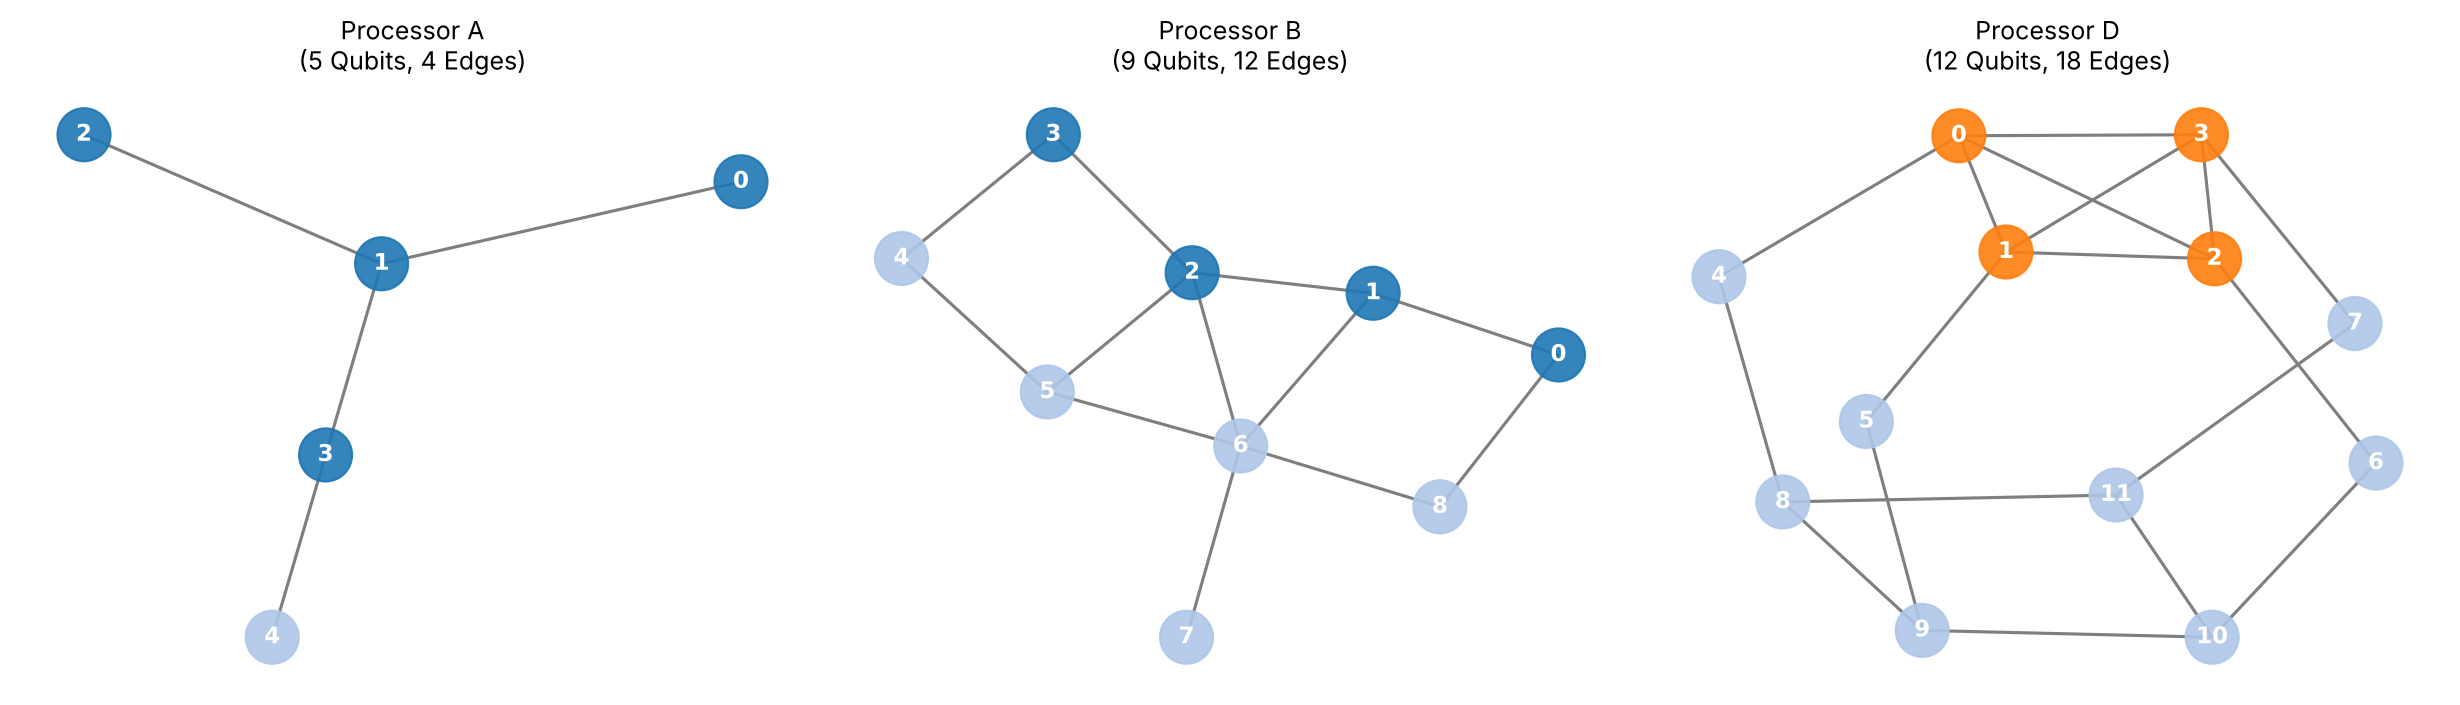

In [4]:
# Load processors and display coupling graph visualization
procs = {
    "processor_A": load_processor("processor_A"),
    "processor_B": load_processor("processor_B"),
    "processor_D": load_processor("processor_D"),
}

save_processor_graphs(procs)
display(Image("results/figures/processor_A_B_graphs.png"))


## 3. Variational Ansätze & Ideal VQE Convergence

We investigate three variational ansatz configurations:
1. **Hardware-Efficient Ansatz (HEA, reps=1):** $RY$ rotations + linear CX (4 parameters).
2. **Hardware-Efficient Ansatz (HEA, reps=2):** Deeper parameterized layers (6 parameters).
3. **Compact Symmetry-Preserving Ansatz:** Givens singlet excitation:
   $$|\psi(\theta)\rangle = \cos(\theta/2)|01\rangle - \sin(\theta/2)|10\rangle$$
   Prepared with exactly 1 $X$ gate, 1 $RY$ rotation, and 1 $CX$ gate.

All ansätze are optimized variationally using the classical COBYLA algorithm.


[HEA reps=1      ] Opt Energy: -1.1373060356 Ha | Error: 2.0267e-07 mHa | Params: 4
[HEA reps=2      ] Opt Energy: -1.1373060354 Ha | Error: 3.6788e-07 mHa | Params: 6
[Compact Singlet ] Opt Energy: -1.1373060355 Ha | Error: 2.2848e-07 mHa | Params: 1


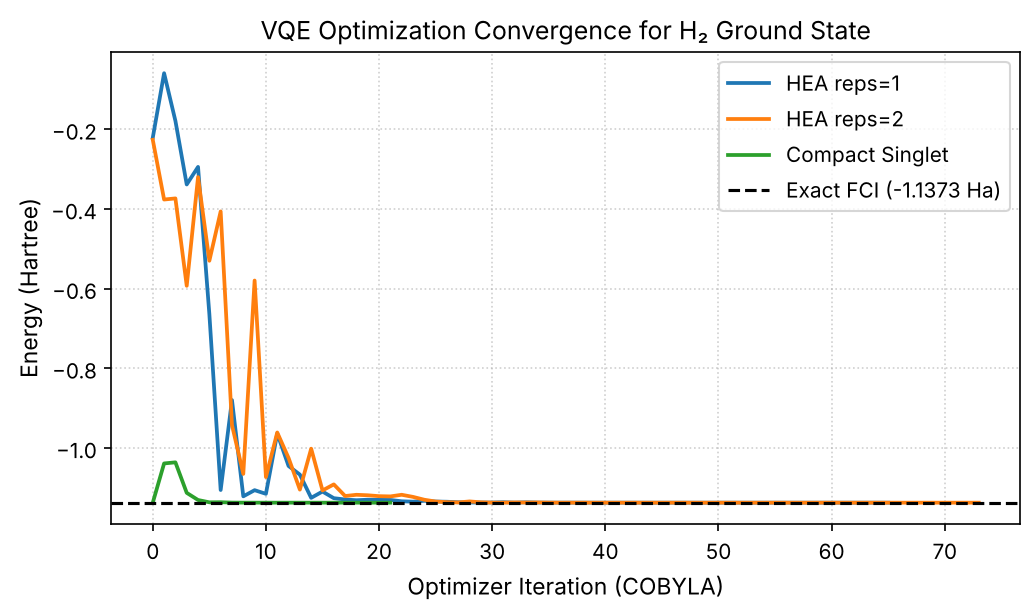

In [5]:
# Run ideal VQE optimization
ansatzes = {
    "HEA reps=1": hea_ansatz(1),
    "HEA reps=2": hea_ansatz(2),
    "Compact Singlet": compact_chemistry_ansatz()
}

vqe_results = {}
histories = {}
for name, ans in ansatzes.items():
    x_opt, e_opt, hist = run_vqe_ideal(ans, seed=42)
    vqe_results[name] = (x_opt, e_opt)
    histories[name] = hist
    err_mHa = abs(e_opt - exact_E) * 1000.0
    print(f"[{name:16s}] Opt Energy: {e_opt:.10f} Ha | Error: {err_mHa:.4e} mHa | Params: {ans.num_parameters}")

plot_vqe_convergence(histories, exact_E)
display(Image("results/figures/vqe_convergence.png"))


## 4. Required Processor A vs Processor B Benchmark (Baseline Noisy Execution)

Under the required baseline:
- Circuits are compiled with Qiskit `transpile(..., optimization_level=1, layout_method='sabre', routing_method='sabre', seed_transpiler=42)`.
- 4096 shots are sampled over 10 repeated simulator seeds (seeds 42 to 51) to compute mean energies and standard errors.
- **Results Table:** Conforms exactly to the Phase 1 Section 5.3 specification.


=== Required Results Table (Section 5.3 Schema) ===


,problem_id,instance_id,architecture,logical_qubits,physical_qubits,objective_or_accuracy,classical_reference,approximation_or_error,cx_count,depth,swap_count,shots,noise_model
0,PS-C1,H2_R0.735_HEA_reps=1,processor_A,2,5,-1.111738,-1.137306,0.025568,1,9,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
1,PS-C1,H2_R0.735_HEA_reps=1,processor_B,2,9,-1.111738,-1.137306,0.025568,1,9,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
2,PS-C1,H2_R0.735_HEA_reps=2,processor_A,2,5,-1.106925,-1.137306,0.030381,2,14,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
3,PS-C1,H2_R0.735_HEA_reps=2,processor_B,2,9,-1.106925,-1.137306,0.030381,2,14,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"


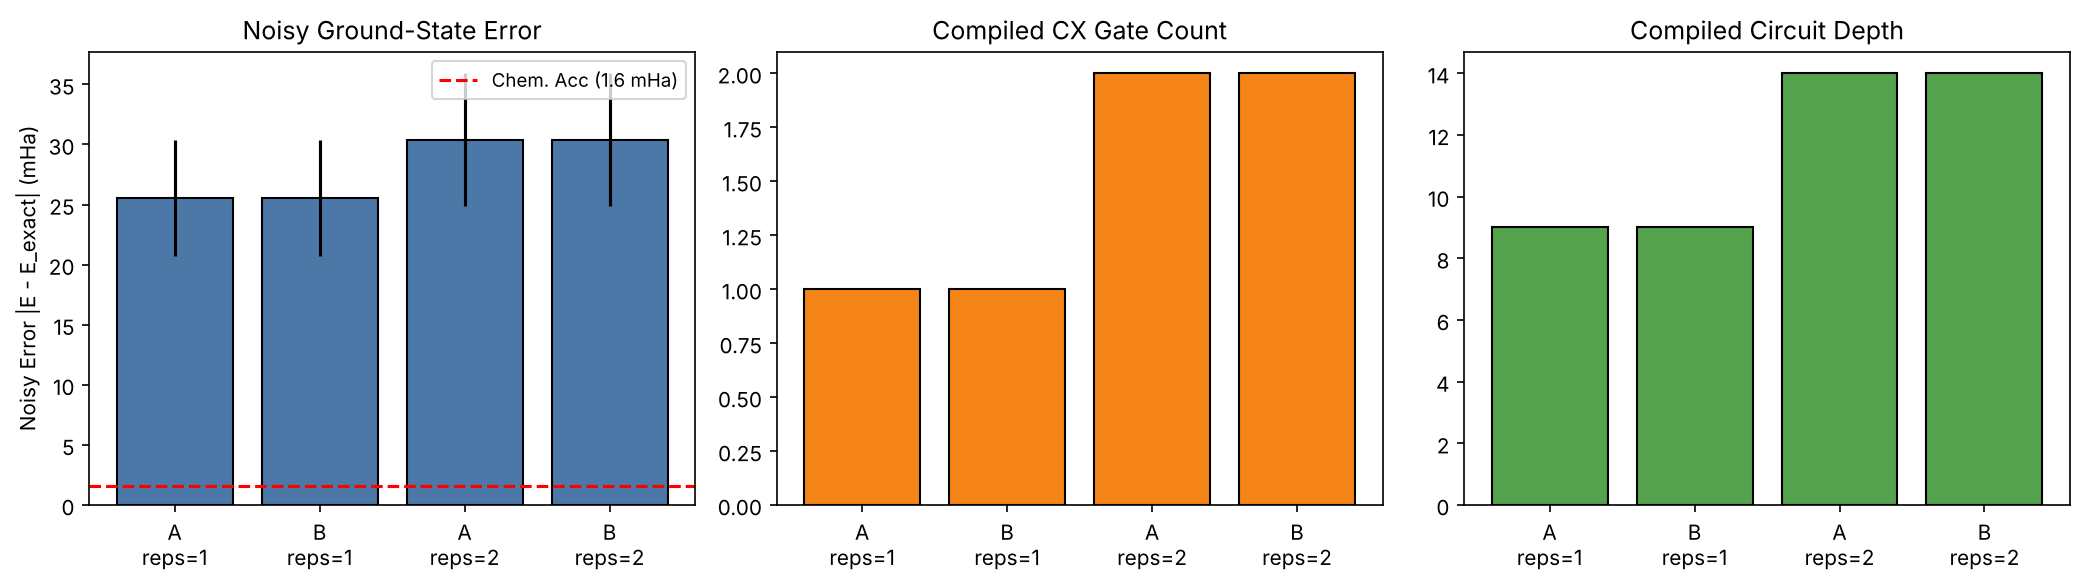

In [6]:
# Load and display the required A/B benchmark table
df_req = pd.read_csv("results/tables/AB_comparison.csv")
print("=== Required Results Table (Section 5.3 Schema) ===")
display(df_req)

display(Image("results/figures/AB_performance.png"))


## 5. Quantum Error Mitigation (Processor A, compact ansatz, 10 seeds)

Stages: (1) raw; (2) readout confusion-matrix inversion; (3) + parity postselection; (4) + zero-noise extrapolation by whole-circuit folding. The **primary ZNE estimator is linear on scales 1 and 3** and is fixed in code, never chosen by comparing to the exact energy; quadratic (1,3,5) is shown for comparison only. Extrapolation amplifies shot noise, so we report mean bias, std over seeds, and the fraction of runs within 1.6 mHa, at the organizer's 4096 shots and at an extra 32768 shots.

,stage,shots,energy_error_hartree,std_hartree,frac_runs_within_chem_acc,within_chemical_accuracy
0,1. Raw Noisy,4096,0.024372,0.004911,0.0,False
1,2. Readout Mitigated,4096,0.007410,0.005042,0.1,False
2,3. Readout + Symmetry,4096,0.004873,0.004510,0.2,False
3,"4. Readout+Sym+ZNE (linear 1,3)",4096,0.001902,0.009205,0.1,False
4,"5. ZNE quadratic (1,3,5), comparison only",4096,0.004309,0.011836,0.0,False
5,1. Raw Noisy,32768,0.022824,0.001673,0.0,False
6,2. Readout Mitigated,32768,0.005460,0.001720,0.0,False
7,3. Readout + Symmetry,32768,0.004109,0.001708,0.1,False
8,"4. Readout+Sym+ZNE (linear 1,3)",32768,0.000460,0.001800,0.7,True
9,"5. ZNE quadratic (1,3,5), comparison only",32768,0.000642,0.002686,0.5,True


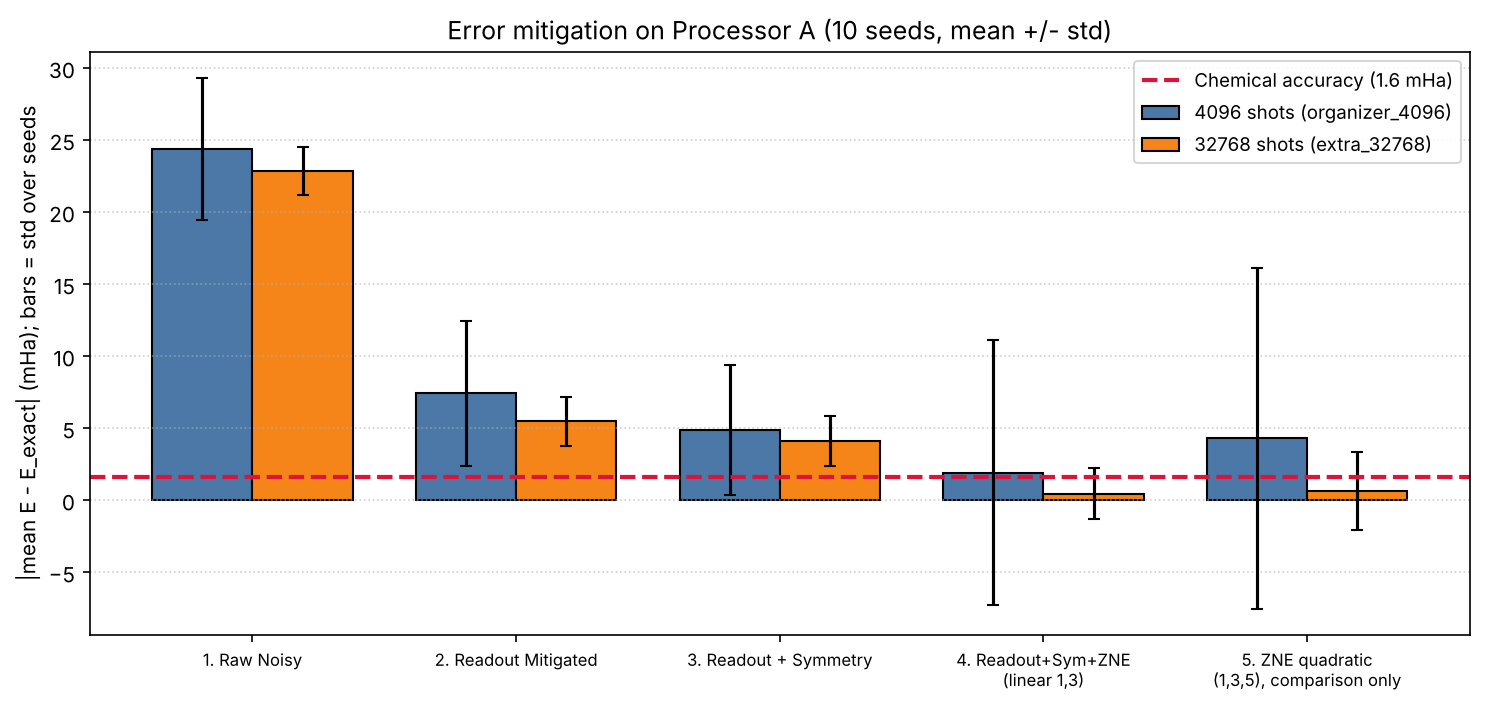

4096 shots, linear ZNE: |bias| = 1.90 mHa, std = 9.21 mHa, runs within 1.6 mHa = 10%
32768 shots, linear ZNE: |bias| = 0.46 mHa, std = 1.80 mHa, runs within 1.6 mHa = 70%


In [7]:
# Multi-seed mitigation table and figure
df_mit = pd.read_csv("results/tables/error_mitigation_results.csv")
display(df_mit[["stage","shots","energy_error_hartree","std_hartree","frac_runs_within_chem_acc","within_chemical_accuracy"]])
display(Image("results/figures/error_mitigation_comparison.png"))

for shots in (4096, 32768):
    r = df_mit[(df_mit.shots == shots) & df_mit.stage.str.startswith("4.")].iloc[0]
    print(f"{shots} shots, linear ZNE: |bias| = {r.energy_error_hartree*1000:.2f} mHa, "
          f"std = {r.std_hartree*1000:.2f} mHa, runs within 1.6 mHa = {r.frac_runs_within_chem_acc:.0%}")

## 6. Architecture Routing Comparison: 4-Qubit Routing Stress Test

**Why A and B are identical on the 2-qubit instance.** It has one CX, and both processors have an adjacent physical pair, so SABRE inserts 0 SWAPs and the compiled circuits coincide.

**Exposing topology.** `full_entangling_4q_ansatz` (RY layer, CX on (0,1),(1,2),(2,3),(3,0),(0,2),(1,3), RY layer) is a *generic routing stress test*, not a UCCSD or chemistry-derived circuit. The table below gives compiled CX, SWAPs and depth for A (tree, no cycles), B (has cycles) and D (K4 core). D is built for exactly this K4 pattern, so its advantage here is by design and should not be read as a general advantage.

,architecture,logical_qubits,physical_qubits,logical_cx,ansatz,compiled_cx,swap_count,compiled_depth,one_qubit_gates,physical_qubits_used
0,processor_A,4,5,6,"full_entangling_4q (routing stress test, not U...",12,2,26,36,4
1,processor_B,4,9,6,"full_entangling_4q (routing stress test, not U...",9,1,18,36,4
2,processor_D,4,12,6,"full_entangling_4q (routing stress test, not U...",6,0,15,36,4


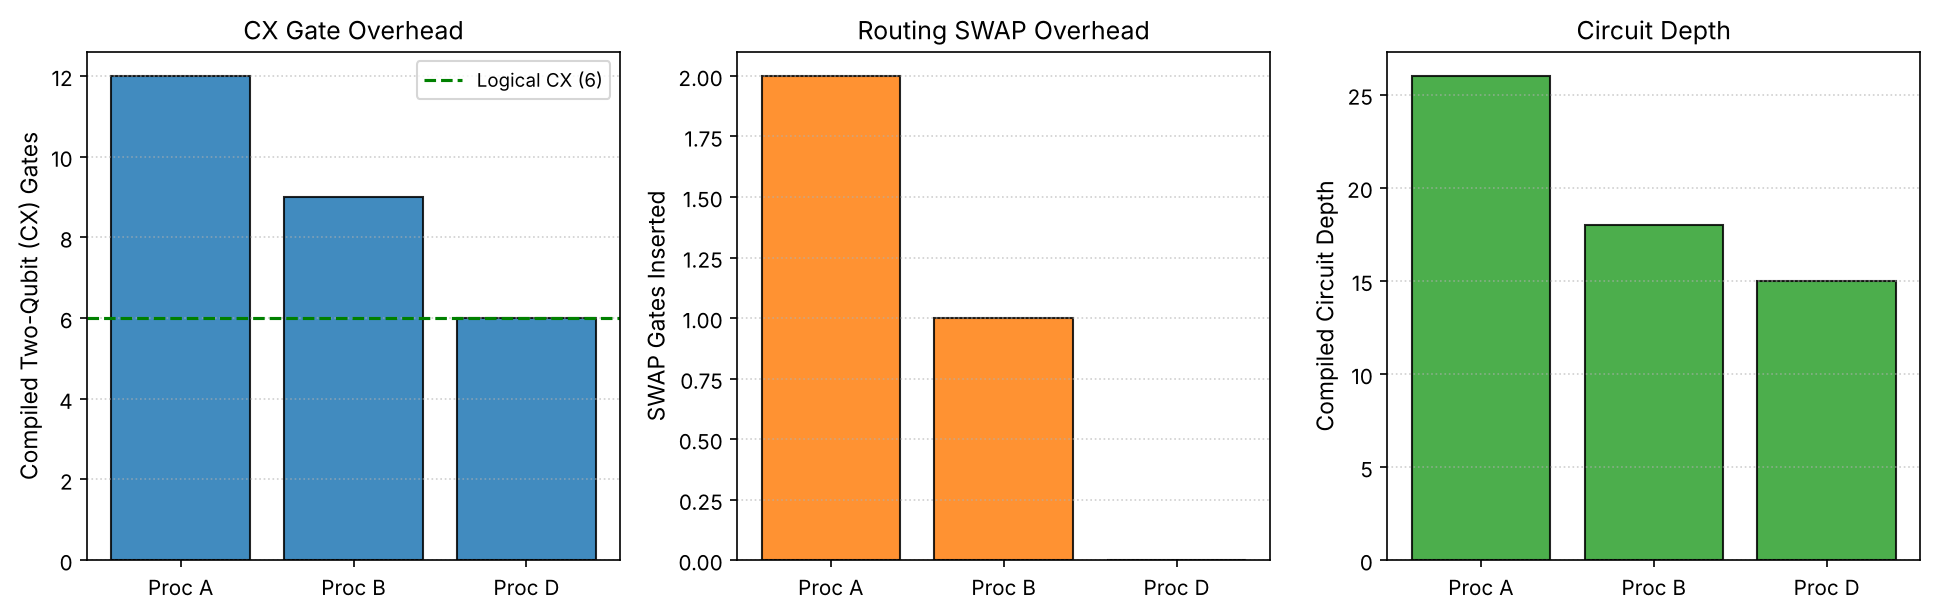

In [8]:
# Load and display 4-qubit routing benchmark results
df_routing = pd.read_csv("results/tables/routing_4qubit_comparison.csv")
display(df_routing)

display(Image("results/figures/routing_overhead_4q.png"))


### Noisy performance of the 4-qubit circuit
Hellinger fidelity between the noisy and ideal output distributions, with identical parameters and seeds on each processor (so differences are paired). Fidelity follows compiled CX count: A (12 CX) < B (9 CX) < D (6 CX). The gaps are small in absolute terms but clear in the paired comparison.

,architecture,compiled_cx,swap_count,compiled_depth,shots,n_runs,hellinger_fidelity_mean,hellinger_fidelity_std,hellinger_fidelity_sem,paired_gain_vs_processor_A,paired_gain_sem
0,processor_A,12,2,24,4096,100,0.985774,0.007229,0.000723,0.000000,0.000000
1,processor_B,9,1,16,4096,100,0.987696,0.006050,0.000605,0.001922,0.000258
2,processor_D,6,0,13,4096,100,0.989607,0.005320,0.000532,0.003833,0.000264


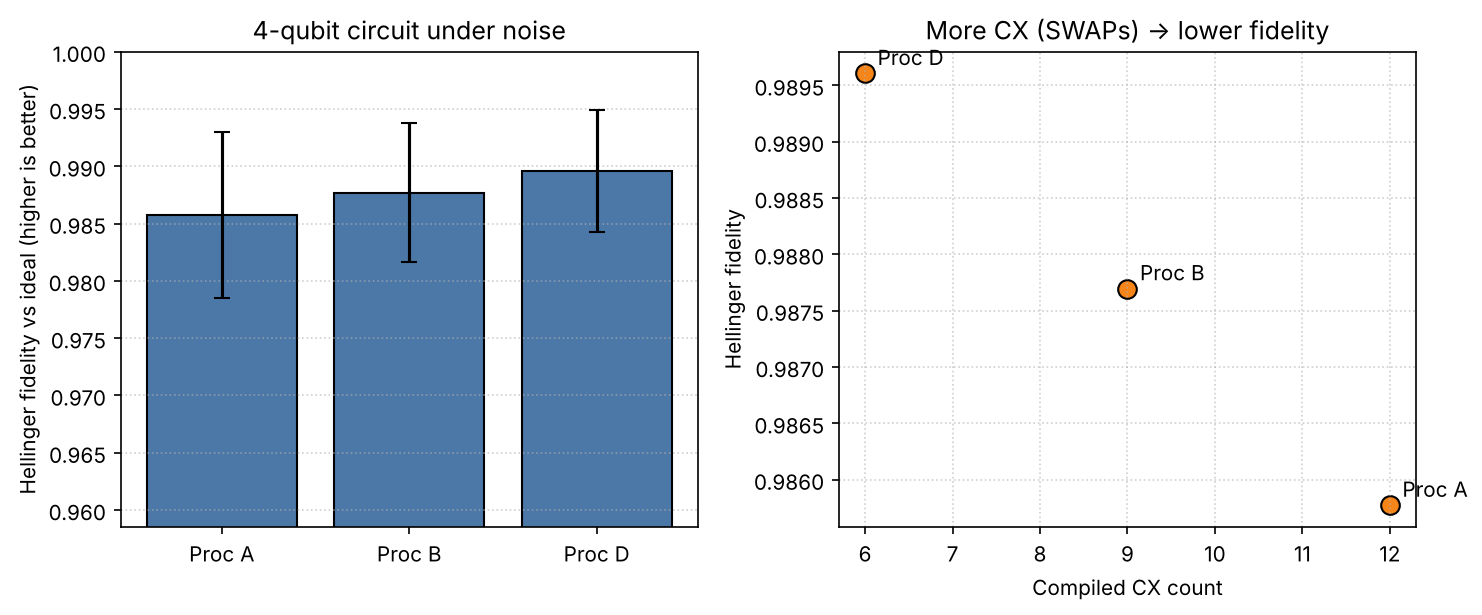

In [9]:
# Noisy performance of the same 4-qubit circuit (10 parameter sets x 10 seeds per processor)
df_nz = pd.read_csv("results/tables/routing_4qubit_noisy_fidelity.csv")
display(df_nz)
display(Image("results/figures/routing_4q_noisy_fidelity.png"))

## 7. Placement Sensitivity

We force every ordered physical placement of the two logical qubits on Processors A (20), B (72) and D (132) and record compiled CX, SWAPs and depth; best/worst placements are then run under noise (10 seeds). The best-placement rows use a forced layout, so their errors differ slightly from the Phase 1 table.

,architecture,placements,mean_cx,max_cx,frac_zero_swap,max_distance
0,processor_A,20,3.400000,7,0.400000,3
1,processor_B,72,3.833333,10,0.333333,4
2,processor_D,132,4.181818,7,0.272727,3


,architecture,placement,phys_q0,phys_q1,distance,cx_count,swap_count,depth,noisy_energy,noisy_std,noisy_error_mHa
0,processor_A,best,0,1,1,1,0,9,-1.113466,0.004588,23.840
1,processor_A,worst,4,2,3,7,2,12,-1.099887,0.005141,37.419
2,processor_B,best,0,1,1,1,0,9,-1.113466,0.004588,23.840
3,processor_B,worst,4,0,4,10,3,15,-1.092133,0.003683,45.173
4,processor_D,best,0,1,1,1,0,9,-1.113466,0.004588,23.840
5,processor_D,worst,11,5,3,7,2,12,-1.098878,0.003758,38.428


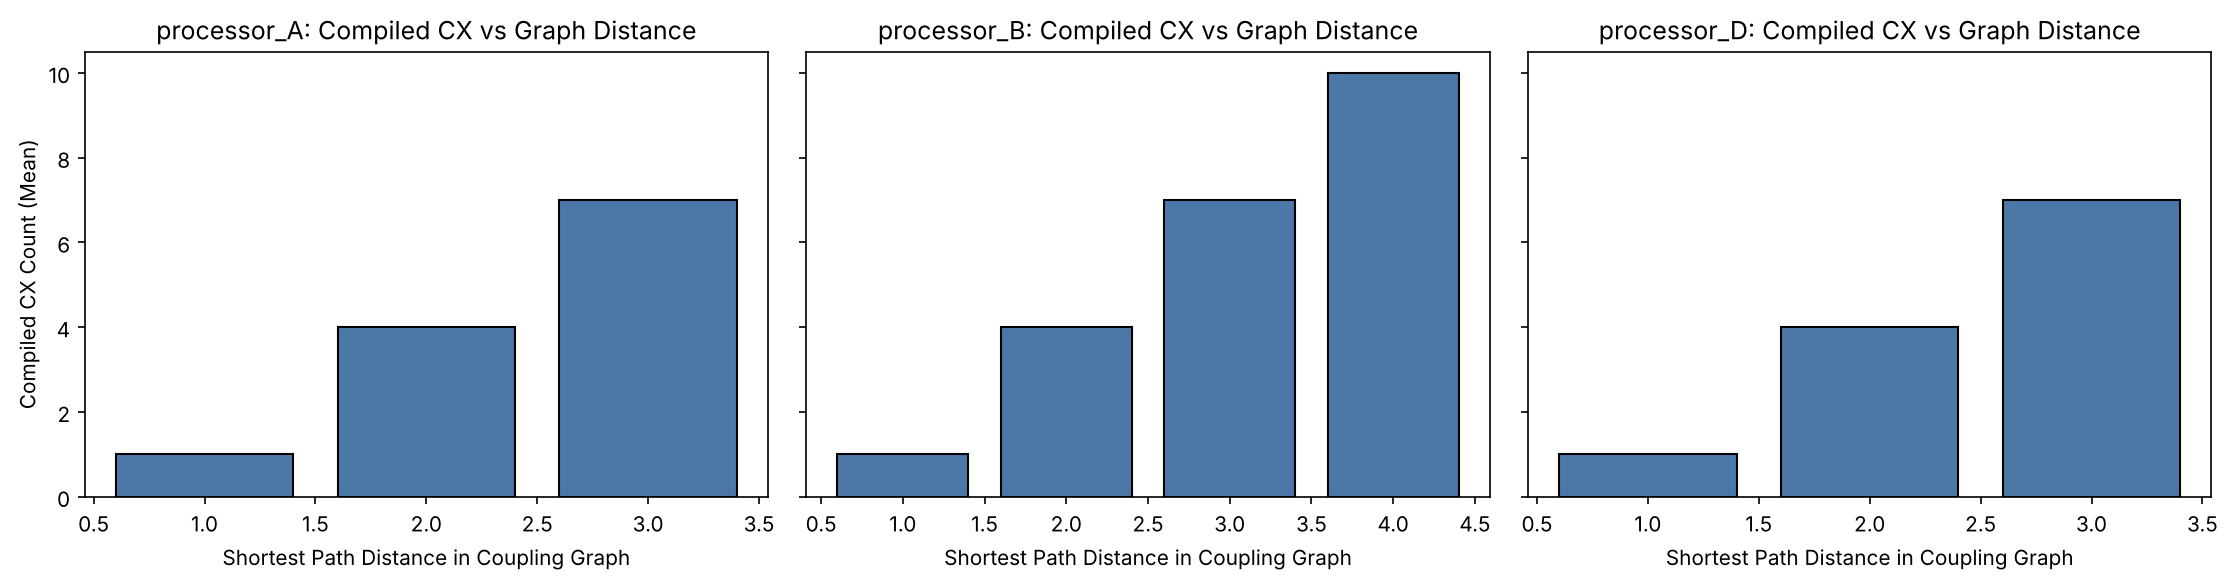

In [10]:
# Display layout sensitivity summaries
df_lay_summ = pd.read_csv("results/tables/layout_sensitivity_summary.csv")
display(HTML("<b>Summary Across Placements:</b>"))
display(df_lay_summ)

df_wc = pd.read_csv("results/tables/placement_noise_effect.csv")
display(HTML("<b>Best vs Worst Placement Noise Degradation:</b>"))
display(df_wc)

display(Image("results/figures/layout_sensitivity.png"))


## 8. Summary and Honest Caveats

| Criterion | What was done | Result (see tables above) |
|---|---|---|
| Correctness | Exact diagonalization, ideal VQE, mitigation study over 10 seeds | Ideal error ~1e-7 mHa; mitigated mean bias well below raw, but run-to-run std at 4096 shots means chemical accuracy is not reliable (see table). |
| Architecture analysis | A vs B required table, 4-qubit routing stress test, placement study | Same results on A and B for 2 qubits; SWAP overhead appears for larger circuits and depends on topology and placement. |
| Processor D | 12 qubits, 18 edges, K4 core + ring, same noise | 0 SWAPs on the K4 stress test; tailored to that circuit, no benefit for the 2-qubit problem. |
| Reproducibility | Pinned requirements (Qiskit 2.5.2, Aer 0.17.2), one-call pipeline, docs built from CSVs | `run_full_benchmark()` then `src/build_docs.py`. |